## Laboratorio 3

### Integrantes

1. Nicolas Mario Romero Colmenares - 202321309
2. Nicolas Rey 

## 1. Importaciones y Exploracion de datos

### 1.1 importacion de librerias

In [38]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

### 1.2 Carga de datos

Se carga el archivo Excel completo y se separan los dos subconjuntos de interés
según el tipo de cupón: Cafetería y Restaurante(<20).

In [22]:
RUTA = './Data/Lab3_Datos.xlsx'

pd.set_option("display.max_columns", None)

data = pd.read_excel(RUTA)

subsets = {
    "Cafeteria": data[data["cupon"] == "Cafetería"].copy(),
    "Restaurante(<20)": data[data["cupon"] == "Restaurante(<20)"].copy()
}

print(data.shape)
for nombre, s in subsets.items():
    print(nombre, s.shape)

(12664, 26)
Cafeteria (3986, 26)
Restaurante(<20) (2776, 26)


El dataset tiene 12.664 registros y 26 variables. Cafetería aporta 3.986 filas y Restaurante(<20) 2.776, es decir, entre ambos cubren cerca de la mitad de los datos.

### 1.3 Calidad de datos

Se revisan nulos, duplicados, columnas constantes, cardinalidad, valores fuera del diccionario, consistencia lógica entre variables y el perfil de cada subconjunto.

In [23]:
def calidad(s, nombre):
    print(f"{nombre}  |  filas: {len(s)}")

    # Nulos
    nulos = s.isna().sum()
    nulos = pd.DataFrame({"n_nulos": nulos, "%": (nulos / len(s) * 100).round(2)})
    print("\n-- Nulos --")
    print(nulos[nulos["n_nulos"] > 0].sort_values("%", ascending=False))

    # Duplicados
    print("\n-- Filas duplicadas exactas:", s.duplicated().sum())

    # Columnas constantes (no aportan información dentro del subconjunto)
    const = [c for c in s.columns if s[c].nunique(dropna=False) <= 1]
    print("-- Columnas constantes:", const)

    # Cardinalidad
    print("\n-- Cardinalidad --")
    print(s.nunique().sort_values(ascending=False))
    print(" ")

for nombre, s in subsets.items():
    calidad(s, nombre)

Cafeteria  |  filas: 3986

-- Nulos --
                                 n_nulos      %
vehiculo                            3949  99.07
frecuencia_cafeteria                  72   1.81
frecuencia_comida_para_llevar         57   1.43
frecuencia_restaurante_20_a_50        55   1.38
frecuencia_restaurante_menos_20       50   1.25
frecuencia_bar                        37   0.93

-- Filas duplicadas exactas: 7
-- Columnas constantes: ['cupon', 'tiempo_cupon_mayor_5min']

-- Cardinalidad --
ocupacion                          25
ingreso                             9
edad                                8
educacion                           6
estado_civil                        5
frecuencia_cafeteria                5
vehiculo                            5
frecuencia_comida_para_llevar       5
frecuencia_bar                      5
hora                                5
frecuencia_restaurante_20_a_50      5
frecuencia_restaurante_menos_20     5
acompanante                         4
destino           

`vehiculo` tiene ~99% de nulos en ambos subconjuntos y no es utilizable. Las variables `frecuencia_*` tienen menos de 2% de nulos. Hay 7 filas duplicadas en cada subconjunto. `cupon` y `tiempo_cupon_mayor_5min` son constantes y no aportan información.

In [24]:
validos = {
    "destino": ["Casa", "Sin lugar urgente", "Trabajo"],
    "acompanante": ["Solo", "Amigo(s)", "Hijo(s)", "Pareja"],
    "clima": ["Soleado", "Lluvioso", "Nevado"],
    "temperatura": [30, 55, 80],
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "vigencia_cupon": ["2 horas", "1 día"],
    "genero": ["Femenino", "Masculino"],
    "estado_civil": ["Soltero(a)", "Casado(a)", "Unión libre", "Divorciado(a)", "Viudo(a)"],
    "tiene_hijos": ["Sí", "No"],
    "vehiculo": ["Mazda5", "Scooter o motocicleta", "Camioneta tipo crossover",
                 "Carro muy viejo para instalarle Onstar", "No conduce"],
    "acepta_cupon": ["Sí", "No"],
    "misma_direccion": ["Sí", "No"],
    "direccion_opuesta": ["Sí", "No"],
    "tiempo_cupon_mayor_5min": ["Sí", "No"],
    "tiempo_cupon_mayor_15min": ["Sí", "No"],
    "tiempo_cupon_mayor_25min": ["Sí", "No"],
}
freq = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
for c in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
          "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]:
    validos[c] = freq

for nombre, s in subsets.items():
    print(f"\n--- {nombre}: valores fuera del diccionario ---")
    for col, ok in validos.items():
        if col not in s.columns:
            print(f"  [!] columna ausente: {col}")
            continue
        raros = set(s[col].dropna().unique()) - set(ok)
        if raros:
            print(f"  {col}: {raros}")


--- Cafeteria: valores fuera del diccionario ---
  vehiculo: {'Carro muy viejo para instalarle Onstar :D'}

--- Restaurante(<20): valores fuera del diccionario ---
  vehiculo: {'Carro muy viejo para instalarle Onstar :D'}


Solo se encontró una inconsistencia: en `vehiculo` aparece "Carro muy viejo para instalarle Onstar :D" (con ":D") en lugar del valor del diccionario. Debe homologarse antes de codificar.

In [25]:
for nombre, s in subsets.items():
    print(f"\n--- {nombre}: chequeos de consistencia ---")

    # clima <-> temperatura (diseño de la encuesta)
    print("\nclima vs temperatura:")
    print(pd.crosstab(s["clima"], s["temperatura"]))

    # misma_direccion y direccion_opuesta no pueden ser ambas 'Sí'
    both = ((s["misma_direccion"] == "Sí") & (s["direccion_opuesta"] == "Sí")).sum()
    print("\nmisma_direccion=Sí y direccion_opuesta=Sí a la vez:", both)
    print("(si son complementarias, una es redundante: revisa multicolinealidad)")
    print(pd.crosstab(s["misma_direccion"], s["direccion_opuesta"]))

    # Distancias anidadas: >25min implica >15min implica >5min
    inc = (
        ((s["tiempo_cupon_mayor_25min"] == "Sí") & (s["tiempo_cupon_mayor_15min"] == "No")) |
        ((s["tiempo_cupon_mayor_15min"] == "Sí") & (s["tiempo_cupon_mayor_5min"] == "No"))
    ).sum()
    print("\nFilas con distancias inconsistentes:", inc)

    # Hijos vs acompañante
    print("\ntiene_hijos vs acompanante='Hijo(s)':")
    print(pd.crosstab(s["tiene_hijos"], s["acompanante"]))


--- Cafeteria: chequeos de consistencia ---

clima vs temperatura:
temperatura   30    55    80
clima                       
Lluvioso       0   224     0
Nevado       303     0     0
Soleado       15  1049  2395

misma_direccion=Sí y direccion_opuesta=Sí a la vez: 0
(si son complementarias, una es redundante: revisa multicolinealidad)
direccion_opuesta   No    Sí
misma_direccion             
No                   0  3239
Sí                 747     0

Filas con distancias inconsistentes: 0

tiene_hijos vs acompanante='Hijo(s)':
acompanante  Amigo(s)  Hijo(s)  Pareja  Solo
tiene_hijos                                 
No                785        4     271  1381
Sí                440      203      32   870

--- Restaurante(<20): chequeos de consistencia ---

clima vs temperatura:
temperatura   30   55    80
clima                      
Lluvioso       0  170     0
Nevado       375    0     0
Soleado      172  493  1566

misma_direccion=Sí y direccion_opuesta=Sí a la vez: 0
(si son complemen

`misma_direccion` y `direccion_opuesta` son perfectamente complementarias (redundantes). Las distancias anidadas son coherentes (0 inconsistencias). `Nevado` solo ocurre a 30°F y `Lluvioso` a 55°F, pero `Soleado` aparece en las tres temperaturas.

In [26]:
for nombre, s in subsets.items():
    print(f"{nombre}")
    for col in ["destino", "acompanante", "clima", "hora", "vigencia_cupon",
                "genero", "edad", "ocupacion", "ingreso"]:
        print(f"\n{col}:")
        print(s[col].value_counts(dropna=False, normalize=True).mul(100).round(1))

Cafeteria

destino:
destino
Sin lugar urgente    54.0
Casa                 23.2
Trabajo              22.8
Name: proportion, dtype: float64

acompanante:
acompanante
Solo        56.5
Amigo(s)    30.7
Pareja       7.6
Hijo(s)      5.2
Name: proportion, dtype: float64

clima:
clima
Soleado     86.8
Nevado       7.6
Lluvioso     5.6
Name: proportion, dtype: float64

hora:
hora
6:00 p.m.     27.4
7:00 a.m.     22.8
10:00 a.m.    22.5
2:00 p.m.     19.9
10:00 p.m.     7.4
Name: proportion, dtype: float64

vigencia_cupon:
vigencia_cupon
2 horas    55.7
1 día      44.3
Name: proportion, dtype: float64

genero:
genero
Femenino     51.3
Masculino    48.7
Name: proportion, dtype: float64

edad:
edad
21             22.1
26             21.1
31             15.5
50 o más       13.6
36             10.1
41              8.1
46              5.5
menor de 21     3.9
Name: proportion, dtype: float64

ocupacion:
ocupacion
Desempleado(a)                                       14.3
Estudiante                   

Ambos subconjuntos son similares: predominan los trayectos sin lugar urgente, conductores solos y clima soleado. `ocupacion` tiene 25 categorías muy desiguales (algunas <1%) y requerirá agrupación.

### 1.4 Distribución de acepta_cupon en cada subconjunto

Se compara la distribución de la variable objetivo en cada subconjunto y su tasa de aceptación según las variables explicativas más relevantes.

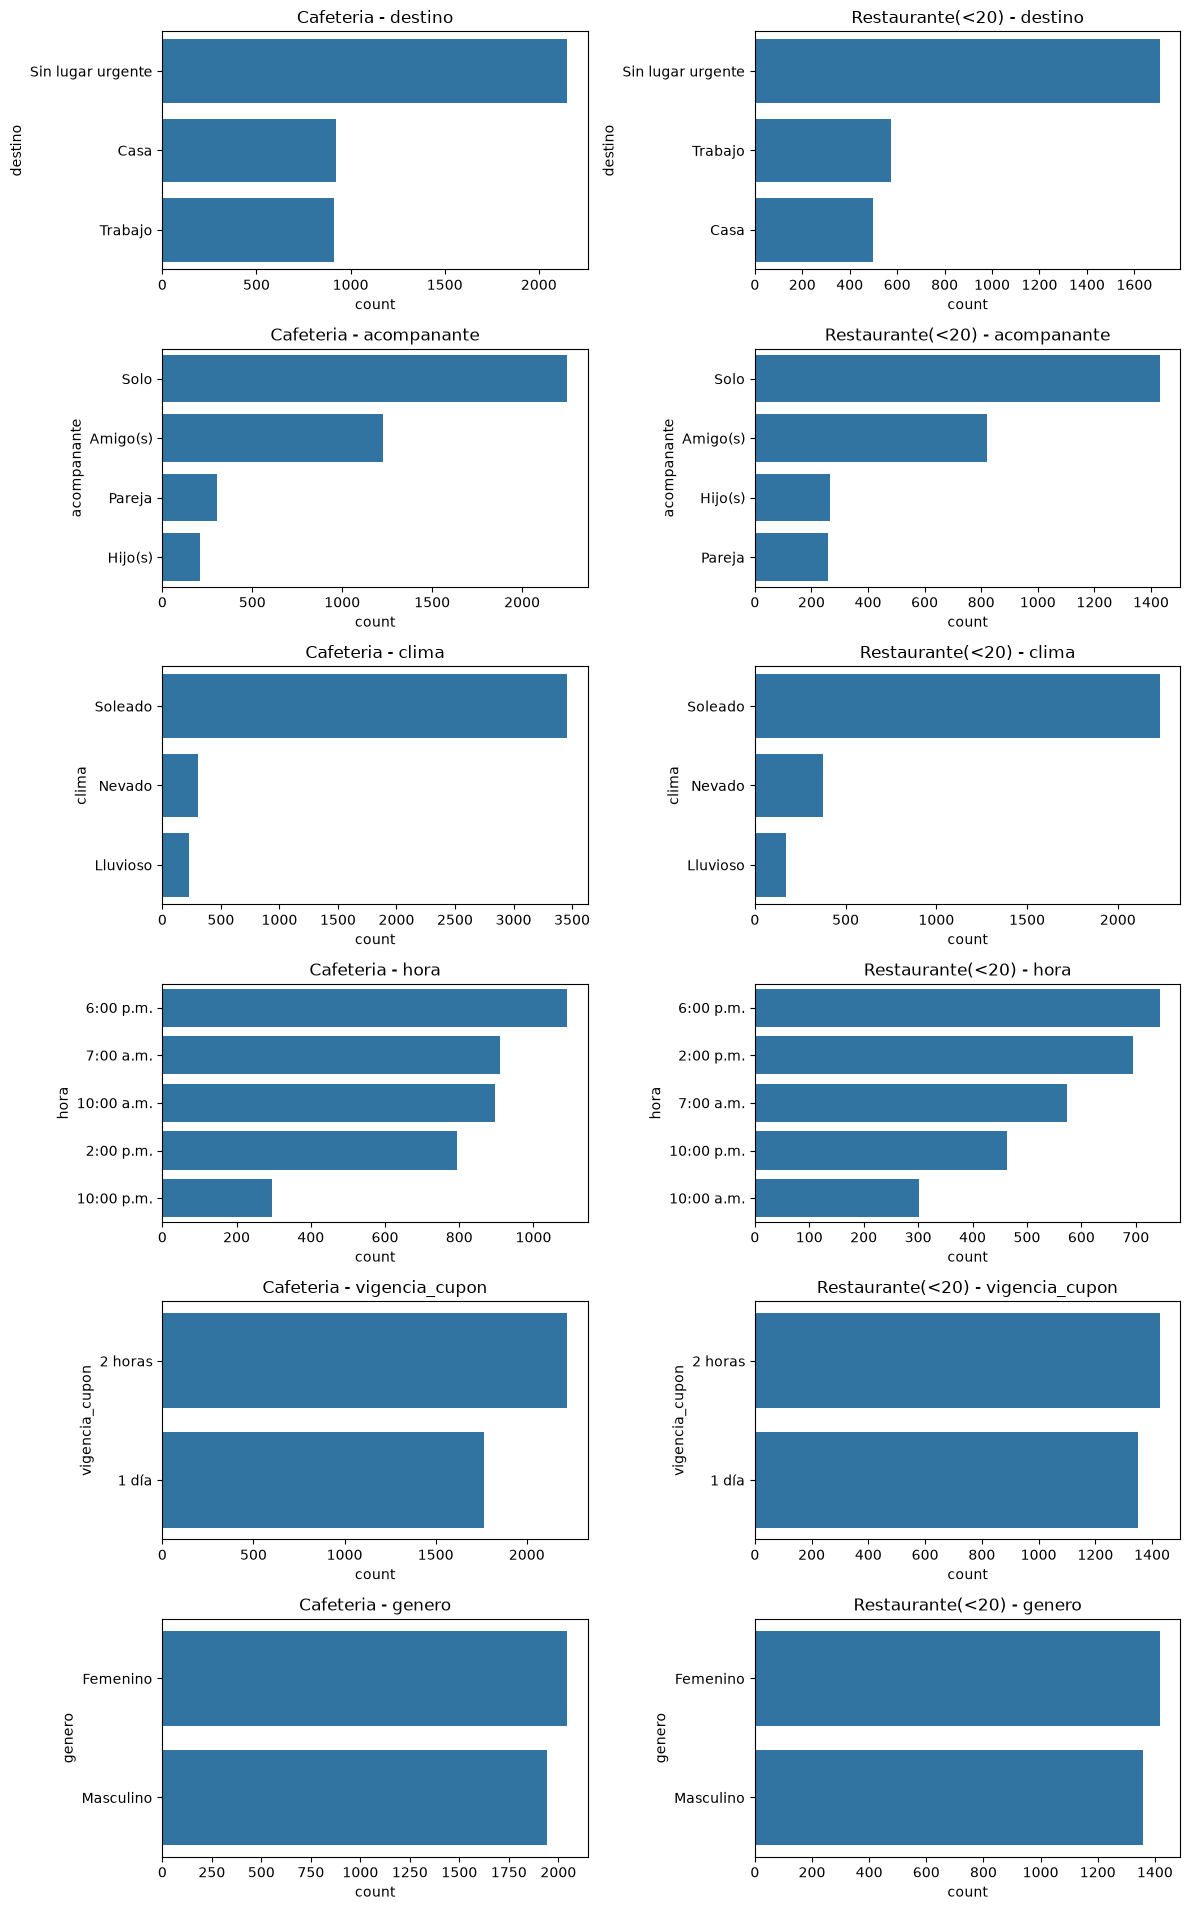

In [27]:
cols_plot = ["destino", "acompanante", "clima", "hora", "vigencia_cupon", "genero"]
fig, axes = plt.subplots(len(cols_plot), 2, figsize=(12, 3.2 * len(cols_plot)))

for i, col in enumerate(cols_plot):
    for j, (nombre, s) in enumerate(subsets.items()):
        sns.countplot(data=s, y=col, ax=axes[i, j],
                      order=s[col].value_counts().index)
        axes[i, j].set_title(f"{nombre} - {col}")
plt.tight_layout()
plt.show()

Las variables explicativas tienen distribuciones parecidas en ambos subconjuntos, con diferencias en `hora` y `clima` (mayor presencia de trayectos nevados y nocturnos en Restaurante(<20)).


Cafeteria
                 n     %
acepta_cupon            
No            1997  50.1
Sí            1989  49.9

Restaurante(<20)
                 n      %
acepta_cupon             
Sí            1962  70.68
No             814  29.32


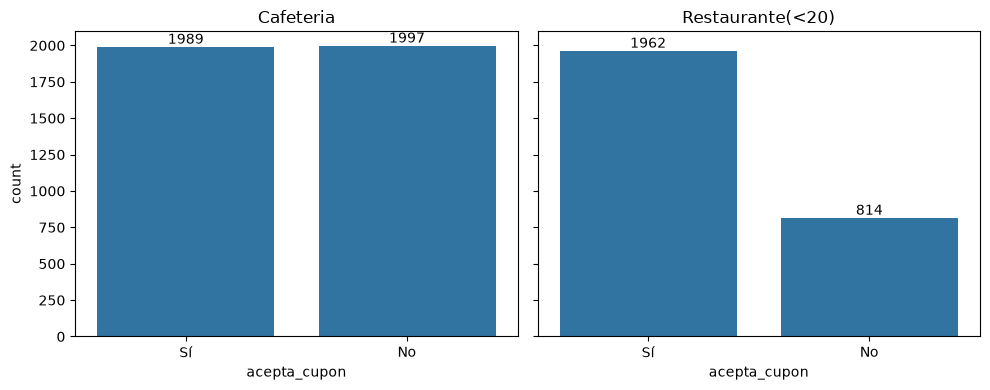

In [28]:
resumen = []
for nombre, s in subsets.items():
    vc = s["acepta_cupon"].value_counts(dropna=False)
    pct = s["acepta_cupon"].value_counts(dropna=False, normalize=True).mul(100).round(2)
    print(f"\n{nombre}")
    print(pd.DataFrame({"n": vc, "%": pct}))
    resumen.append(pct.rename(nombre))

# Gráfico lado a lado
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (nombre, s) in zip(axes, subsets.items()):
    sns.countplot(data=s, x="acepta_cupon", order=["Sí", "No"], ax=ax)
    ax.set_title(nombre)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout()
plt.show()

Cafetería está balanceada (49,9% Sí / 50,1% No), mientras que Restaurante(<20) está desbalanceada hacia la aceptación (70,7% Sí / 29,3% No). Esto afectará la elección de métricas y el entrenamiento de los modelos.

In [29]:
def tasa_aceptacion(s, col, orden=None):
    t = (s.assign(acepta=(s["acepta_cupon"] == "Sí").astype(int))
           .groupby(col)["acepta"].agg(["mean", "count"]))
    t["mean"] = (t["mean"] * 100).round(1)
    t = t.rename(columns={"mean": "% acepta", "count": "n"})
    return t.reindex(orden) if orden else t

for nombre, s in subsets.items():
    print(f"{nombre}")
    for col in ["vigencia_cupon", "hora", "clima", "destino", "acompanante",
                "tiempo_cupon_mayor_15min", "direccion_opuesta"]:
        print(f"\n{col}")
        print(tasa_aceptacion(s, col))

# Relación con la frecuencia de visita (ordinal)
print("\nCafetería ~ frecuencia_cafeteria")
print(tasa_aceptacion(subsets["Cafeteria"], "frecuencia_cafeteria", freq))
print("\nRestaurante(<20) ~ frecuencia_restaurante_menos_20")
print(tasa_aceptacion(subsets["Restaurante(<20)"], "frecuencia_restaurante_menos_20", freq))

Cafeteria

vigencia_cupon
                % acepta     n
vigencia_cupon                
1 día               58.4  1764
2 horas             43.2  2222

hora
            % acepta     n
hora                      
10:00 a.m.      64.0   897
10:00 p.m.      42.0   295
2:00 p.m.       54.7   793
6:00 p.m.       41.2  1091
7:00 a.m.       44.7   910

clima
          % acepta     n
clima                   
Lluvioso      51.8   224
Nevado        43.2   303
Soleado       50.4  3459

destino
                   % acepta     n
destino                          
Casa                   36.1   925
Sin lugar urgente      58.0  2151
Trabajo                44.7   910

acompanante
             % acepta     n
acompanante                
Amigo(s)         59.6  1225
Hijo(s)          48.3   207
Pareja           56.8   303
Solo             43.8  2251

tiempo_cupon_mayor_15min
                          % acepta     n
tiempo_cupon_mayor_15min                
No                            54.8  1917
Sí            

En ambos subconjuntos aceptan más los cupones de 1 día, con destino "sin lugar urgente" y los conductores con mayor frecuencia de visita. En cambio, `direccion_opuesta` tiene efecto inverso entre subconjuntos, así que conviene modelarlos por separado.

## 2. Limpieza y preparacion de datos

Con base en los hallazgos de la exploración, se eliminan variables inútiles, se tratan duplicados y nulos, se agrupan categorías raras y se codifican las variables para modelar.

### 2.1 Eliminacion de datos

In [30]:
COLS_ELIMINAR = ["vehiculo", "cupon", "tiempo_cupon_mayor_5min", "direccion_opuesta"]

def limpiar(s):
    s = s.drop_duplicates()            # primero duplicados, con todas las columnas originales
    s = s.drop(columns=COLS_ELIMINAR)
    return s.reset_index(drop=True)

clean = {n: limpiar(s) for n, s in subsets.items()}

for n, s in clean.items():
    print(f"{n}: {subsets[n].shape} -> {s.shape}")

Cafeteria: (3986, 26) -> (3979, 22)
Restaurante(<20): (2776, 26) -> (2769, 22)


In [31]:
UMBRAL = 3.0   # % mínimo para conservar la categoría

freq_ocup = pd.concat(clean.values())["ocupacion"].value_counts(normalize=True).mul(100)
principales = freq_ocup[freq_ocup >= UMBRAL].index.tolist()
print(f"Categorías conservadas ({len(principales)}):", principales)

for n, s in clean.items():
    s["ocupacion"] = s["ocupacion"].where(s["ocupacion"].isin(principales), "Otras")
    print(n, "->", s["ocupacion"].nunique(), "categorías de ocupación")

Categorías conservadas (10): ['Desempleado(a)', 'Estudiante', 'Computación y Matemáticas', 'Ventas y afines', 'Educación, Formación y Bibliotecología', 'Gerencia', 'Artes, Diseño, Entretenimiento, Deportes y Medios', 'Apoyo Administrativo y de Oficina', 'Jubilado(a)', 'Negocios y Finanzas']
Cafeteria -> 11 categorías de ocupación
Restaurante(<20) -> 11 categorías de ocupación


### 2.2 Codificacion

In [32]:
ORDINALES = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo",
                  "Estudios universitarios sin título", "Técnico/Tecnólogo",
                  "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499",
                "$37.500 - $49.999", "$50.000 - $62.499", "$62.500 - $74.999",
                "$75.000 - $87.499", "$87.500 - $99.999", "$100.000 o más"],
    **{c: freq for c in ["frecuencia_bar", "frecuencia_cafeteria",
                         "frecuencia_comida_para_llevar",
                         "frecuencia_restaurante_menos_20",
                         "frecuencia_restaurante_20_a_50"]},
}
BINARIAS = ["tiene_hijos", "misma_direccion",
            "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min"]
NOMINALES = ["destino", "acompanante", "clima", "estado_civil", "ocupacion", "genero"]

def codificar(s):
    s = s.copy()

    for col, orden in ORDINALES.items():
        mapa = {v: i for i, v in enumerate(orden)}
        cod = s[col].map(lambda v: mapa.get(str(v)) if pd.notna(v) else np.nan)
        sin_mapa = s.loc[s[col].notna() & cod.isna(), col].unique()
        if len(sin_mapa):
            raise ValueError(f"'{col}': valores sin mapear {sin_mapa}")
        s[col] = cod.astype(float)

    for col in BINARIAS + ["acepta_cupon"]:
        s[col] = s[col].map({"Sí": 1, "No": 0})
        assert s[col].notna().all(), f"nulos inesperados en {col}"

    # NUEVO: vigencia_cupon como binaria (1 = vigencia de 1 día)
    s["vigencia_cupon"] = s["vigencia_cupon"].map({"2 horas": 0, "1 día": 1})
    assert s["vigencia_cupon"].notna().all(), "valores inesperados en vigencia_cupon"

    s = pd.get_dummies(s, columns=NOMINALES, drop_first=True, dtype=int)

    # Verificación: no debe quedar ninguna columna de texto
    no_num = s.select_dtypes(exclude="number").columns.tolist()
    assert not no_num, f"columnas sin codificar: {no_num}"
    return s

prep = {n: codificar(s) for n, s in clean.items()}

for n, s in prep.items():
    print(f"{n}: {s.shape}, nulos restantes: {s.isna().sum().sum()}")

Cafeteria: (3979, 38), nulos restantes: 271
Restaurante(<20): (2769, 38), nulos restantes: 174


### 2.3 Justificacion de la preparacion de datos

| Desicion | Evidencia de la exploracion | Justificacion |
| --- | --- | --- |
| Eliminar la columna vehiculo | 99% de nulos en ambos subconjuntos | No hay información suficiente para imputar de forma razonable |
| Eliminar columnas cupon y tiempo_cupon_mayor_5min | Constantes en ambos subconjuntos | Sin varianza no aportan al análisis ni a un modelo |
| Eliminar columna direccion_opuesta | Es el complemento exacto de misma_direccion | Es redundante y generaría multicolinealidad perfecta | 
| Eliminar 7 duplicados por subconjunto | 7 filas duplicadas exactas en cada uno | No hay identificador de encuestado, así que no se pueden distinguir de un registro repetido. El impacto es mínimo|
| Imputar con la moda las frecuencias | Menos de 2% de nulos cada una | Eliminar filas perdería muestra, y con tan pocos nulos la moda introduce un sesgo mínimo. Se ajusta solo con entrenamiento para no filtrar información|
| Conservar temperatura junto a clima | Soleado aparece en 30°F, 55°F y 80°F | No es redundante con clima, porque distingue días soleados fríos y cálidos |
| Agrupar ocupacion en pocas categorias | 25 categorías, varias con menos de 2% | Evita columnas casi vacías al codificar y reduce el riesgo de sobreajuste |
| Codificar ordinales con enteros | hora, edad, educacion, ingreso y las frecuencias tienen orden natural | Conserva la relación de orden sin multiplicar columnas |
| Codificar nominales con one-hot y binarias con 0/1 | destino, acompanante, clima, estado_civil, ocupacion, genero tienen si o Sí/No | Estas variables no tienen orden |
| Mantener los dos subconjuntos separados y usar partición estratificada | Cafetería 49,9% Sí y Restaurante 70,7% Sí | Los comportamientos difieren, y estratificar mantiene la proporción de la clase objetivo en entrenamiento y prueba |
| No tocar las filas con tiene_hijos=No y acompanante=Hijo | Solo 4 y 3 casos | Pueden ser sobrinos o nietos, y el efecto es despreciable |
| No tratar valores atípicos | No hay variables numéricas continuas (temperatura solo toma 3 valores) | No aplica |
| Codificar vigencia_cupon como binaria | Dos categorías; es el factor con mayor efecto en la aceptación | Al tener solo dos niveles, una columna 0/1 basta y evita crear una dummy equivalente |

Se eliminaron 4 columnas y 7 duplicados por subconjunto, se imputaron los nulos de `frecuencia_*` con la moda (solo entrenamiento) y se codificaron las variables. La partición estratificada conserva el balance de `acepta_cupon` (~50% Cafetería, ~71% Restaurante).

### 3 Modelos de regresion logistica

### 3.1 Particion de datos

In [33]:
splits = {}
for n, s in prep.items():
    X, y = s.drop(columns="acepta_cupon"), s["acepta_cupon"]
    splits[n] = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    print(n, "| train:", splits[n][0].shape, "| test:", splits[n][1].shape)

Cafeteria | train: (3183, 37) | test: (796, 37)
Restaurante(<20) | train: (2215, 37) | test: (554, 37)


### 3.2 Pipeline

In [34]:
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=42)),
])

Cs = [0.01, 0.1, 1, 10, 100]
pesos = [None, "balanced"]

param_grid = [
    {"clf__solver": ["liblinear"], "clf__penalty": ["l1", "l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["saga"], "clf__penalty": ["l1", "l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["saga"], "clf__penalty": ["elasticnet"],
     "clf__l1_ratio": [0.25, 0.5, 0.75],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["lbfgs", "newton-cg"], "clf__penalty": ["l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
]

### 3.3 Busqueda con validacion cruzada

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy"}

modelos = {}
for n, (X_tr, X_te, y_tr, y_te) in splits.items():
    gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="roc_auc",
                      cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    modelos[n] = gs
    print(f"\n{n}")
    print("  Mejores hiperparámetros:", gs.best_params_)
    print(f"  ROC-AUC CV: {gs.best_score_:.4f}")


Cafeteria
  Mejores hiperparámetros: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0.25, 'clf__penalty': 'elasticnet', 'clf__solver': 'saga'}
  ROC-AUC CV: 0.7743

Restaurante(<20)
  Mejores hiperparámetros: {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l1', 'clf__solver': 'saga'}
  ROC-AUC CV: 0.7397


### 3.5 Resultados de busqueda

In [41]:
cols = ["param_clf__solver", "param_clf__penalty", "param_clf__C",
        "param_clf__class_weight", "mean_test_roc_auc",
        "mean_test_f1", "mean_test_accuracy"]

for n, gs in modelos.items():
    res = pd.DataFrame(gs.cv_results_)
    print(f"\n{n} - Top 5 combinaciones")
    print(res.sort_values("rank_test_roc_auc")[cols].head(5).round(4).to_string(index=False))

    print(f"\n{n} - Mejor ROC-AUC por solver y penalización")
    print(res.groupby(["param_clf__solver", "param_clf__penalty"])["mean_test_roc_auc"]
             .max().round(4))


Cafeteria - Top 5 combinaciones
param_clf__solver param_clf__penalty  param_clf__C param_clf__class_weight  mean_test_roc_auc  mean_test_f1  mean_test_accuracy
             saga         elasticnet           0.1                balanced             0.7743        0.7092              0.7110
             saga         elasticnet           0.1                     NaN             0.7743        0.7079              0.7103
             saga                 l1           1.0                balanced             0.7743        0.7067              0.7085
        liblinear                 l1           1.0                balanced             0.7742        0.7072              0.7091
        liblinear                 l1           1.0                     NaN             0.7742        0.7064              0.7085

Cafeteria - Mejor ROC-AUC por solver y penalización
param_clf__solver  param_clf__penalty
lbfgs              l2                    0.7741
liblinear          l1                    0.7742
            

### 3.6 Coeficientes

In [42]:
for n, gs in modelos.items():
    cols_X = splits[n][0].columns
    coef = pd.Series(gs.best_estimator_.named_steps["clf"].coef_[0], index=cols_X)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
    print(f"\n{n} - 10 coeficientes de mayor magnitud")
    print(top.round(3))
    print("Coeficientes en 0 (eliminados por regularización):", int((coef == 0).sum()))


Cafeteria - 10 coeficientes de mayor magnitud
frecuencia_cafeteria         0.966
destino_Sin lugar urgente    0.506
vigencia_cupon               0.386
hora                        -0.380
misma_direccion              0.255
frecuencia_bar              -0.224
tiempo_cupon_mayor_15min    -0.207
acompanante_Solo            -0.165
estado_civil_Unión libre    -0.146
tiempo_cupon_mayor_25min     0.135
dtype: float64
Coeficientes en 0 (eliminados por regularización): 2

Restaurante(<20) - 10 coeficientes de mayor magnitud
vigencia_cupon                     0.542
clima_Soleado                      0.341
destino_Sin lugar urgente          0.333
acompanante_Hijo(s)               -0.210
acompanante_Solo                  -0.188
educacion                         -0.156
temperatura                        0.128
frecuencia_restaurante_menos_20    0.128
estado_civil_Soltero(a)            0.119
hora                              -0.113
dtype: float64
Coeficientes en 0 (eliminados por regularización): 11
